# ChromaGrade — Full-Dataset RBC Severity Detector (YOLO26, 50 epochs)
### Fine-tunes the **latest Ultralytics YOLO model (YOLO26)** on pseudo-labelled RBC boxes, using *every* field image in the dataset (no sampling cap)

This notebook is adapted from `RECENT_RANyolo-anemia.ipynb`. It keeps the same dataset loading,
Otsu-based per-cell segmentation, and central-pallor-ratio pseudo-labelling logic (Sections 1–7 of
the original), but changes two things:

1. **Every field image is used** to build the YOLO training set — the original notebook's
   `N_FIELDS_FOR_PSEUDO_LABELS = 300` sampling cap is removed.
2. **The detector itself is upgraded from YOLOv8s to YOLO26s** — YOLO26 is Ultralytics' current
   recommended stable model generation (released Jan 2026), replacing YOLOv8/YOLO11 as the default
   choice for new training runs. It's trained for **50 epochs**, same as the reference run.

As before: classes (`Normochromic` / `Mild_Hypochromic` / `Severely_Hypochromic`) and boxes are
**pseudo-labels** derived from the same central-pallor-ratio rule already validated in
`Ran_Normochromic_HemaConvNeXt_MIL_...ipynb` — not independent expert ground truth. This notebook
does **not** reload the trained MIL classifier / CBC imputer / scaler, since detector training only
needs the field images plus the pseudo-label rule, not the bag-level model.


---

**Added on top of the original notebook:** Section 8a (confusion matrix + PR/F1 curves via `val(plots=True)`), Section 8b (EigenCAM on the trained YOLO26 backbone), and Section 8c (D-RISE per-detection saliency + localization-validation hit-rate). These slot in right after the existing Section 8 validation call and use the same `yolo_model` / `fields_df` / `CLASSES` this notebook already builds — nothing about the dataset loading, pseudo-labelling, or training sections (1–7) was changed.

## 1. Setup

In [1]:
import os, re, glob, json, zipfile, warnings, random, math
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

from skimage.feature import peak_local_max
from skimage.segmentation import watershed
from scipy import ndimage as ndi

from tqdm.auto import tqdm

# Reproducibility
SEED = 42
random.seed(SEED); np.random.seed(SEED)

plt.rcParams["figure.dpi"] = 150
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["font.size"] = 10

import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


Device: cuda


## 2. Get the dataset + the patch-labels table into the Kaggle session

Needs the same two bundles as the original notebook:

| What | Contains |
|---|---|
| `anemia_500.zip` (or unzipped) | `Original_Images/`, `RGB_Segmented/`, `Binary_Segmented/`, `cbc.csv`, `morphology.csv` |
| `pallor_mil_results.zip` (or unzipped) | `tables/patch_pallor_labels.csv` (one row per field, with `record_id`, `patch_id`, image paths) |

**Attach both as Kaggle Datasets** via **+ Add Input** (preferred), or set the Drive-link fallbacks below.
This notebook only reads `patch_pallor_labels.csv` from the results bundle — it does **not** need the
trained model checkpoint, CBC imputer, or scaler.


In [2]:
CONTENT_ROOT = "/kaggle/input/datasets/ayeshaafzal2946/anemia-yolo-latest-ver/anemia_500"
RESULTS_ROOT = "/kaggle/input/datasets/ayeshaafzal2946/anemia-yolo-latest-ver/Normochromic_pallor_mil_results"
KAGGLE_INPUT_ROOT = "/kaggle/input/datasets/ayeshaafzal2946/anemia-yolo-latest-ver"
os.makedirs(CONTENT_ROOT, exist_ok=True)
os.makedirs(RESULTS_ROOT, exist_ok=True)

# Fallback only -- leave blank if you've attached both via '+ Add Input'.
DATASET_DRIVE_LINK = ""    # e.g. "https://drive.google.com/file/d/XXXXXXXX/view?usp=sharing"  (anemia_500.zip)
RESULTS_DRIVE_LINK = ""    # e.g. "https://drive.google.com/file/d/YYYYYYYY/view?usp=sharing"  (pallor_mil_results.zip)


def _drive_id(link):
    m = re.search(r"/d/([a-zA-Z0-9_-]+)", link) or re.search(r"id=([a-zA-Z0-9_-]+)", link)
    return m.group(1) if m else link.strip()


def _zip_is_intact(path):
    if not (os.path.exists(path) and os.path.getsize(path) > 0):
        return False
    if not zipfile.is_zipfile(path):
        return False
    try:
        with zipfile.ZipFile(path) as z:
            return z.testzip() is None
    except Exception:
        return False


def _download_from_drive(link, out_path, label, max_attempts=3):
    import gdown
    file_id = _drive_id(link)
    for attempt in range(1, max_attempts + 1):
        if os.path.exists(out_path):
            os.remove(out_path)
        print(f"[{label}] Downloading from Google Drive (attempt {attempt}/{max_attempts})...")
        gdown.download(id=file_id, output=out_path, quiet=False, fuzzy=True)
        if _zip_is_intact(out_path):
            print(f"[{label}] Download OK -- zip integrity verified.")
            return out_path
        print(f"[{label}] Attempt {attempt} produced a corrupt/incomplete zip."
              if attempt < max_attempts else f"[{label}] Attempt {attempt} still corrupt.")
    raise RuntimeError(f"[{label}] Could not download an intact zip after {max_attempts} attempts. "
                        f"Attach it as a Kaggle Dataset instead.")


def _find_under_input(filename):
    hits = glob.glob(os.path.join(KAGGLE_INPUT_ROOT, "**", filename), recursive=True)
    return hits[0] if hits else None


def _find_dir_under_input(dirname):
    hits = [p for p in glob.glob(os.path.join(KAGGLE_INPUT_ROOT, "**", dirname), recursive=True)
            if os.path.isdir(p)]
    return hits[0] if hits else None


def get_dataset_root():
    d = _find_dir_under_input("Original_Images")
    if d:
        print("Found dataset already unzipped under /kaggle/input.")
        return os.path.dirname(d)

    zpath = _find_under_input("anemia_500.zip")
    if zpath is None:
        for cand in glob.glob(os.path.join(KAGGLE_INPUT_ROOT, "**", "*.zip"), recursive=True):
            with zipfile.ZipFile(cand) as z:
                if any("Original_Images" in n for n in z.namelist()):
                    zpath = cand
                    break
    if zpath is not None:
        print(f"Found dataset zip attached as a Kaggle Dataset: {zpath}")
        assert _zip_is_intact(zpath), f"Found {zpath} but it failed the integrity check -- re-upload."
        with zipfile.ZipFile(zpath) as z:
            z.extractall(CONTENT_ROOT)
        return os.path.dirname(glob.glob(os.path.join(CONTENT_ROOT, "**", "Original_Images"), recursive=True)[0])

    if DATASET_DRIVE_LINK.strip():
        print("No Kaggle-attached dataset found -- falling back to the Google Drive link.")
        zpath = _download_from_drive(DATASET_DRIVE_LINK, "/kaggle/working/anemia_500.zip", "dataset")
        with zipfile.ZipFile(zpath) as z:
            z.extractall(CONTENT_ROOT)
        return os.path.dirname(glob.glob(os.path.join(CONTENT_ROOT, "**", "Original_Images"), recursive=True)[0])

    raise FileNotFoundError("Couldn't find the anemia_500 dataset. Attach it via '+ Add Input', "
                             "or set DATASET_DRIVE_LINK above.")


def get_patch_labels_csv():
    hit = _find_under_input("patch_pallor_labels.csv")
    if hit:
        print("Found patch_pallor_labels.csv already unzipped under /kaggle/input.")
        return hit

    zpath = _find_under_input("pallor_mil_results.zip")
    if zpath is None:
        for cand in glob.glob(os.path.join(KAGGLE_INPUT_ROOT, "**", "*.zip"), recursive=True):
            with zipfile.ZipFile(cand) as z:
                if any("patch_pallor_labels.csv" in n for n in z.namelist()):
                    zpath = cand
                    break
    if zpath is not None:
        print(f"Found results zip attached as a Kaggle Dataset: {zpath}")
        assert _zip_is_intact(zpath), f"Found {zpath} but it failed the integrity check -- re-upload."
        with zipfile.ZipFile(zpath) as z:
            z.extractall(RESULTS_ROOT)
        hits = glob.glob(os.path.join(RESULTS_ROOT, "**", "patch_pallor_labels.csv"), recursive=True)
        if hits:
            return hits[0]

    if RESULTS_DRIVE_LINK.strip():
        print("No Kaggle-attached results found -- falling back to the Google Drive link.")
        zpath = _download_from_drive(RESULTS_DRIVE_LINK, "/kaggle/working/pallor_mil_results.zip", "results")
        with zipfile.ZipFile(zpath) as z:
            z.extractall(RESULTS_ROOT)
        hits = glob.glob(os.path.join(RESULTS_ROOT, "**", "patch_pallor_labels.csv"), recursive=True)
        if hits:
            return hits[0]

    raise FileNotFoundError("Couldn't find patch_pallor_labels.csv. Attach the results bundle via "
                             "'+ Add Input', or set RESULTS_DRIVE_LINK above.")


ROOT = get_dataset_root()
print("Dataset root:", ROOT)
PATCH_LABELS_CSV = get_patch_labels_csv()
print("Patch labels CSV:", PATCH_LABELS_CSV)


Found dataset already unzipped under /kaggle/input.
Dataset root: /kaggle/input/datasets/ayeshaafzal2946/anemia-yolo-latest-ver/anemia_500/anemia_500
Found patch_pallor_labels.csv already unzipped under /kaggle/input.
Patch labels CSV: /kaggle/input/datasets/ayeshaafzal2946/anemia-yolo-latest-ver/Normochromic_pallor_mil_results/tables/patch_pallor_labels.csv


In [3]:
ORIG_DIR = os.path.join(ROOT, "Original_Images")
RGB_DIR  = os.path.join(ROOT, "RGB_Segmented")
BIN_DIR  = os.path.join(ROOT, "Binary_Segmented")

for name, d in [("Original_Images", ORIG_DIR), ("RGB_Segmented", RGB_DIR), ("Binary_Segmented", BIN_DIR)]:
    n = len(glob.glob(os.path.join(d, "*")))
    print(f"{name}: {n} files")


Original_Images: 6000 files
RGB_Segmented: 6000 files
Binary_Segmented: 6000 files


## 3. Configuration — classes, colours, pallor thresholds (unchanged from the reference)

In [4]:
BASE_CLASSES = ["Normochromic", "Mild_Hypochromic", "Severely_Hypochromic"]
LABEL2IDX = {c: i for i, c in enumerate(BASE_CLASSES)}
IDX2LABEL = {i: c for c, i in LABEL2IDX.items()}

DISPLAY_NAMES = {
    "Normochromic": "Normochromic",
    "Mild_Hypochromic": "Mild Hypochromic",
    "Severely_Hypochromic": "Severely Hypochromic",
}

def pretty(name):
    return DISPLAY_NAMES.get(name, name)

# green = normochromic, yellow = mild, red = severe
SEVERITY_COLORS_HEX = {
    "Normochromic": "#2ecc71",
    "Mild_Hypochromic": "#f1c40f",
    "Severely_Hypochromic": "#e74c3c",
}
SEVERITY_COLORS_BGR = {
    "Normochromic": (60, 200, 70),
    "Mild_Hypochromic": (10, 200, 241),
    "Severely_Hypochromic": (60, 60, 231),
}

PALLOR_THRESH_MILD = 0.33
PALLOR_THRESH_SEVERE = 0.50

def label_from_ratio(ratio):
    if ratio is None or (isinstance(ratio, float) and math.isnan(ratio)):
        return None
    if ratio <= PALLOR_THRESH_MILD:
        return "Normochromic"
    elif ratio <= PALLOR_THRESH_SEVERE:
        return "Mild_Hypochromic"
    else:
        return "Severely_Hypochromic"

print("Classes:", BASE_CLASSES)


Classes: ['Normochromic', 'Mild_Hypochromic', 'Severely_Hypochromic']


## 4. Rebuild the field-level table — **all** fields, every patient

Loads `patch_pallor_labels.csv` and resolves each field's image paths for this session. This gives
us the full list of `(record_id, patch_id, rgb_path, bin_path)` used to build the YOLO dataset in
Section 7 — every field, not a sample.

In [5]:
def _tolerant_read_csv(path, expected_cols=None):
    for kwargs in [dict(), dict(engine="python", on_bad_lines="skip"),
                   dict(engine="python", sep=None, on_bad_lines="skip")]:
        try:
            df = pd.read_csv(path, **kwargs)
            if expected_cols is None or expected_cols.issubset(df.columns):
                return df
        except Exception:
            continue
    with open(path, "r", errors="replace") as f:
        preview = [next(f, "") for _ in range(5)]
    print(f"Could not parse {path} with any strategy. First 5 raw lines:")
    for line in preview:
        print(repr(line[:200]))
    raise ValueError(f"{path} could not be read -- likely a corrupted/truncated download.")


patch_df = _tolerant_read_csv(PATCH_LABELS_CSV, expected_cols={"record_id", "patch_id"})
print("Loaded patch_df:", patch_df.shape)

def _resolve_path(row, colname, folder):
    p = row[colname] if colname in row and isinstance(row[colname], str) else None
    if p and os.path.exists(p):
        return p
    return os.path.join(folder, row["filename"]) if "filename" in row else p

patch_df["rgb_path"] = patch_df.apply(lambda r: _resolve_path(r, "rgb_path", RGB_DIR), axis=1)
patch_df["bin_path"] = patch_df.apply(lambda r: _resolve_path(r, "bin_path", BIN_DIR), axis=1)

fields_df = patch_df[["record_id", "patch_id", "rgb_path", "bin_path"]].drop_duplicates().reset_index(drop=True)
n_missing = (~fields_df["rgb_path"].apply(lambda p: isinstance(p, str) and os.path.exists(p))).sum()
print(f"Total unique fields: {len(fields_df)}")
print(f"Fields whose RGB image could not be located: {n_missing} / {len(fields_df)}")
fields_df.head()


Loaded patch_df: (6000, 8)
Total unique fields: 6000
Fields whose RGB image could not be located: 0 / 6000


,record_id,patch_id,rgb_path,bin_path
0,1,1,/kaggle/input/datasets/ayeshaafzal2946/anemia-...,/kaggle/input/datasets/ayeshaafzal2946/anemia-...
1,1,2,/kaggle/input/datasets/ayeshaafzal2946/anemia-...,/kaggle/input/datasets/ayeshaafzal2946/anemia-...
2,1,3,/kaggle/input/datasets/ayeshaafzal2946/anemia-...,/kaggle/input/datasets/ayeshaafzal2946/anemia-...
3,1,4,/kaggle/input/datasets/ayeshaafzal2946/anemia-...,/kaggle/input/datasets/ayeshaafzal2946/anemia-...
4,1,5,/kaggle/input/datasets/ayeshaafzal2946/anemia-...,/kaggle/input/datasets/ayeshaafzal2946/anemia-...


## 5. Detect individual RBCs — Otsu segmentation directly from the RGB image

Same detector as the reference notebook: Otsu threshold → distance-transform + watershed split of
touching cells → area/circularity filtering. Also carries the per-cell central-pallor-ratio function
used to assign each detected cell its pseudo-label class.

In [6]:
def _otsu_foreground_mask(rgb_field_bgr, min_area, max_area):
    gray = cv2.cvtColor(rgb_field_bgr, cv2.COLOR_BGR2GRAY)
    blur = cv2.GaussianBlur(gray, (5, 5), 0)
    _, otsu = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    raw = (otsu > 0).astype(np.uint8)

    best_mask, best_score = raw, -1
    for cand in (raw, 1 - raw):
        clean = cv2.morphologyEx(cand, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
        clean = cv2.morphologyEx(clean, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
        n, _, stats, _ = cv2.connectedComponentsWithStats(clean, 8)
        plausible = sum(1 for k in range(1, n) if min_area <= stats[k, cv2.CC_STAT_AREA] <= max_area)
        if plausible > best_score:
            best_score, best_mask = plausible, clean
    return best_mask, best_score


def detect_cells_in_field(bin_path, rgb_path, min_area_frac=0.0006, max_area_frac=0.05,
                           min_circularity=0.40, min_peak_distance=10, debug=False):
    bgr = cv2.imread(rgb_path, cv2.IMREAD_COLOR)
    if bgr is None:
        return []

    h, w = bgr.shape[:2]
    min_area = min_area_frac * h * w
    max_area = max_area_frac * h * w

    fg, n_plausible = _otsu_foreground_mask(bgr, min_area, max_area)
    if debug:
        print(f"  foreground fraction: {fg.mean():.3f}, plausible-sized components: {n_plausible}")
    if fg.sum() == 0:
        return []

    dist = cv2.distanceTransform(fg, cv2.DIST_L2, 5)
    coords = peak_local_max(dist, min_distance=min_peak_distance, labels=fg)
    if len(coords) == 0:
        return []

    peak_mask = np.zeros(dist.shape, dtype=bool)
    peak_mask[tuple(coords.T)] = True
    markers, _ = ndi.label(peak_mask)
    labels_ws = watershed(-dist, markers, mask=fg)

    detections = []
    for lbl in np.unique(labels_ws):
        if lbl == 0:
            continue
        cell_mask = labels_ws == lbl
        area = int(cell_mask.sum())
        if area < min_area or area > max_area:
            continue

        ys, xs = np.where(cell_mask)
        x0, x1, y0, y1 = xs.min(), xs.max(), ys.min(), ys.max()
        bw, bh = x1 - x0 + 1, y1 - y0 + 1

        contours, _ = cv2.findContours(cell_mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        if not contours:
            continue
        perim = cv2.arcLength(max(contours, key=cv2.contourArea), True)
        if perim == 0:
            continue
        circularity = 4 * math.pi * area / (perim ** 2)
        if circularity < min_circularity:
            continue

        detections.append({
            "bbox": (int(x0), int(y0), int(bw), int(bh)),
            "mask": cell_mask,
            "area": area,
            "circularity": float(circularity),
        })

    if debug:
        print(f"  final detections after area/circularity filtering: {len(detections)}")
    return detections


def compute_cell_pallor_ratio(cell_mask, rgb_field_bgr):
    ys, xs = np.where(cell_mask)
    if len(xs) < 30:
        return None
    x0, x1, y0, y1 = xs.min(), xs.max(), ys.min(), ys.max()
    pad = 2
    y0p, y1p = max(0, y0 - pad), min(rgb_field_bgr.shape[0], y1 + pad + 1)
    x0p, x1p = max(0, x0 - pad), min(rgb_field_bgr.shape[1], x1 + pad + 1)

    crop_bgr = rgb_field_bgr[y0p:y1p, x0p:x1p]
    crop_mask = cell_mask[y0p:y1p, x0p:x1p]
    if crop_bgr.size == 0 or crop_mask.sum() < 20:
        return None

    lab = cv2.cvtColor(crop_bgr, cv2.COLOR_BGR2LAB).astype(np.float32)
    L = lab[..., 0]
    a = lab[..., 1] - 128.0
    b = lab[..., 2] - 128.0
    chroma = np.sqrt(a ** 2 + b ** 2)

    dist = cv2.distanceTransform(crop_mask.astype(np.uint8), cv2.DIST_L2, 5)
    if dist.max() == 0:
        return None
    central = dist > (0.35 * dist.max())

    L_in_mask = L[crop_mask > 0]
    if len(L_in_mask) == 0:
        return None
    l_thresh = np.percentile(L_in_mask, 60)
    pale = (L >= l_thresh) & (chroma < np.percentile(chroma[crop_mask > 0], 60)) & crop_mask & central

    denom = int((central & crop_mask).sum())
    if denom == 0:
        return None
    return float(np.clip(pale.sum() / denom, 0.0, 1.0))


### Sanity check before running this over the full dataset

Testing detection on record 1, patch 1:
  foreground fraction: 0.307, plausible-sized components: 77
  final detections after area/circularity filtering: 104
-> 104 RBCs detected


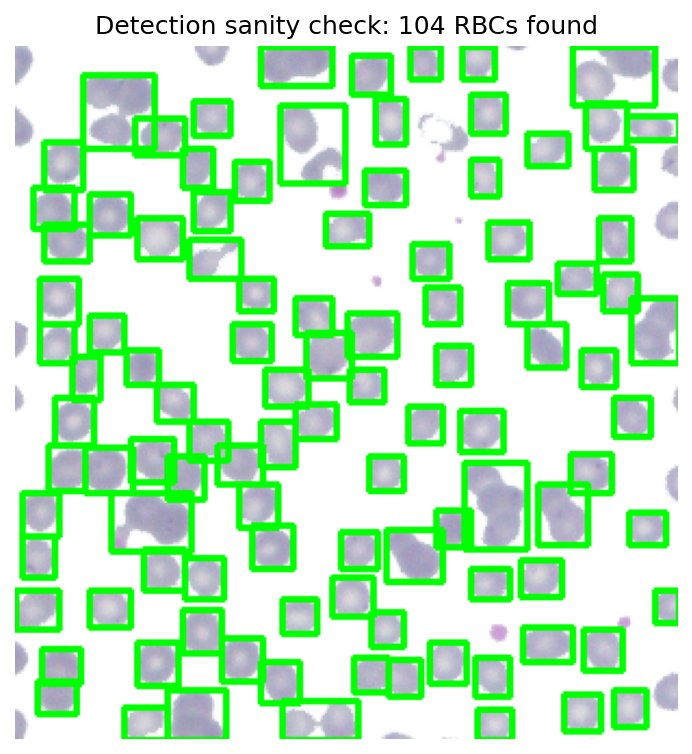

In [7]:
_dbg_row = fields_df.iloc[0]
print(f"Testing detection on record {_dbg_row['record_id']}, patch {_dbg_row['patch_id']}:")
_dbg_dets = detect_cells_in_field(_dbg_row["bin_path"], _dbg_row["rgb_path"], debug=True)
print(f"-> {len(_dbg_dets)} RBCs detected")

if len(_dbg_dets) > 0:
    _dbg_bgr = cv2.imread(_dbg_row["rgb_path"], cv2.IMREAD_COLOR)
    _dbg_rgb = cv2.cvtColor(_dbg_bgr, cv2.COLOR_BGR2RGB).copy()
    for d in _dbg_dets:
        x, y, w, h = d["bbox"]
        cv2.rectangle(_dbg_rgb, (x, y), (x + w, y + h), (0, 255, 0), 2)
    plt.figure(figsize=(6, 6))
    plt.imshow(_dbg_rgb)
    plt.title(f"Detection sanity check: {len(_dbg_dets)} RBCs found")
    plt.axis("off")
    plt.show()
else:
    print("\nZero detections -- try lowering min_circularity (e.g. 0.30) or min_area_frac.")


## 6. Build the YOLO-format dataset from **every** field image

Unlike the reference notebook (which capped this step at `N_FIELDS_FOR_PSEUDO_LABELS = 300` fields
for speed), this runs over **all** fields in `fields_df` — every image in the dataset gets processed,
pseudo-labelled, and added to the training set. The train/val split is still done at the **patient**
(`record_id`) level, 80/20, so no patient's cells leak across the split.

This step is the slow part (per-field Otsu segmentation + per-cell pallor ratio, over every image) —
expect it to take noticeably longer than the 300-field sample run.

In [8]:
YOLO_ROOT = "/kaggle/working/yolo_dataset"

for sub in ["images/train", "images/val", "labels/train", "labels/val"]:
    os.makedirs(f"{YOLO_ROOT}/{sub}", exist_ok=True)

# Patient-level split (80/20)
rng = np.random.RandomState(SEED)
all_rids = fields_df["record_id"].drop_duplicates().sample(frac=1.0, random_state=SEED).tolist()
n_val = max(1, int(0.2 * len(all_rids)))
val_rids = set(all_rids[:n_val])

fields_to_process = fields_df  # ALL fields -- no sampling cap
print(f"Processing all {len(fields_to_process)} fields (patients: {len(all_rids)}, "
      f"val patients: {len(val_rids)})")

n_boxes_total = 0
n_fields_with_boxes = 0
class_box_counts = {c: 0 for c in BASE_CLASSES}

for _, row in tqdm(fields_to_process.iterrows(), total=len(fields_to_process), desc="Pseudo-labelling ALL fields"):
    rid, pid = int(row["record_id"]), int(row["patch_id"])
    split = "val" if rid in val_rids else "train"

    if not isinstance(row["rgb_path"], str) or not os.path.exists(row["rgb_path"]):
        continue
    bgr = cv2.imread(row["rgb_path"], cv2.IMREAD_COLOR)
    if bgr is None:
        continue
    h, w = bgr.shape[:2]

    dets = detect_cells_in_field(row["bin_path"], row["rgb_path"])
    lines = []
    for d in dets:
        ratio = compute_cell_pallor_ratio(d["mask"], bgr)
        label = label_from_ratio(ratio)
        if label is None or label not in LABEL2IDX:
            continue
        cls_idx = LABEL2IDX[label]
        x, y, bw, bh = d["bbox"]
        xc, yc = (x + bw / 2) / w, (y + bh / 2) / h
        nbw, nbh = bw / w, bh / h
        lines.append(f"{cls_idx} {xc:.6f} {yc:.6f} {nbw:.6f} {nbh:.6f}")
        class_box_counts[label] += 1
        n_boxes_total += 1

    if not lines:
        continue
    n_fields_with_boxes += 1

    stem = f"{rid}_{pid}"
    img_out = f"{YOLO_ROOT}/images/{split}/{stem}.jpg"
    lbl_out = f"{YOLO_ROOT}/labels/{split}/{stem}.txt"
    cv2.imwrite(img_out, bgr)
    with open(lbl_out, "w") as f:
        f.write("\n".join(lines) + "\n")

print(f"\nFields with at least one pseudo-labelled box: {n_fields_with_boxes} / {len(fields_to_process)}")
print(f"Total pseudo-labelled boxes: {n_boxes_total}")
print("Class distribution of pseudo-labelled boxes:")
for c in BASE_CLASSES:
    print(f"  {pretty(c)}: {class_box_counts[c]}")

CLASSES = [c for c in BASE_CLASSES if class_box_counts[c] > 0]

data_yaml = f'''path: {YOLO_ROOT}
train: images/train
val: images/val
names:
{chr(10).join(f'  {i}: {c}' for i, c in enumerate(CLASSES))}
'''
with open(f"{YOLO_ROOT}/data.yaml", "w") as f:
    f.write(data_yaml)
print("\ndata.yaml:\n" + data_yaml)


Processing all 6000 fields (patients: 500, val patients: 100)


Pseudo-labelling ALL fields:   0%|          | 0/6000 [00:00<?, ?it/s]


Fields with at least one pseudo-labelled box: 6000 / 6000
Total pseudo-labelled boxes: 503543
Class distribution of pseudo-labelled boxes:
  Normochromic: 188197
  Mild Hypochromic: 193257
  Severely Hypochromic: 122089

data.yaml:
path: /kaggle/working/yolo_dataset
train: images/train
val: images/val
names:
  0: Normochromic
  1: Mild_Hypochromic
  2: Severely_Hypochromic



## 6b. Exploratory analysis of the pseudo-labelled dataset

Before spending a training run on it, look at what Section 6 actually produced: how the
pseudo-labelled boxes split across classes and train/val, how big the boxes are, and — as a
**heatmap** — *where inside the field images* each severity class tends to be detected. A skewed
or off-centre spatial distribution would be a red flag for the Otsu/pallor-ratio pipeline, not just
the detector.


In [9]:
def _load_yolo_boxes(yolo_root, classes, splits=("train", "val")):
    """Re-reads the YOLO-format label .txt files written in Section 6 into a tidy dataframe."""
    rows = []
    for split in splits:
        lbl_dir = f"{yolo_root}/labels/{split}"
        for lbl_path in sorted(glob.glob(os.path.join(lbl_dir, "*.txt"))):
            stem = os.path.splitext(os.path.basename(lbl_path))[0]
            with open(lbl_path) as f:
                for line in f:
                    parts = line.strip().split()
                    if len(parts) != 5:
                        continue
                    cls_idx, xc, yc, bw, bh = parts
                    cls_idx = int(cls_idx)
                    cls_name = classes[cls_idx] if cls_idx < len(classes) else f"cls{cls_idx}"
                    rows.append({
                        "field": stem, "split": split, "class": cls_name,
                        "xc": float(xc), "yc": float(yc),
                        "bw": float(bw), "bh": float(bh),
                        "area_frac": float(bw) * float(bh),
                    })
    return pd.DataFrame(rows)

boxes_df = _load_yolo_boxes(YOLO_ROOT, CLASSES)
print(f"Loaded {len(boxes_df)} pseudo-labelled boxes from {boxes_df['field'].nunique()} fields "
      f"({(boxes_df['split'] == 'train').sum()} train boxes, {(boxes_df['split'] == 'val').sum()} val boxes)")
boxes_df.head()


Loaded 503543 pseudo-labelled boxes from 6000 fields (396149 train boxes, 107394 val boxes)


,field,split,class,xc,yc,bw,bh,area_frac
0,100_1,train,Mild_Hypochromic,0.102941,0.023438,0.062092,0.046875,0.002911
1,100_1,train,Mild_Hypochromic,0.591503,0.023438,0.052288,0.046875,0.002451
2,100_1,train,Normochromic,0.490196,0.035937,0.058824,0.053125,0.003125
3,100_1,train,Severely_Hypochromic,0.830065,0.040625,0.052288,0.062500,0.003268
4,100_1,train,Normochromic,0.308824,0.032813,0.101307,0.065625,0.006648


class  Normochromic  Mild_Hypochromic  Severely_Hypochromic
split                                                      
train        149370            151275                 95504
val           38827             41982                 26585


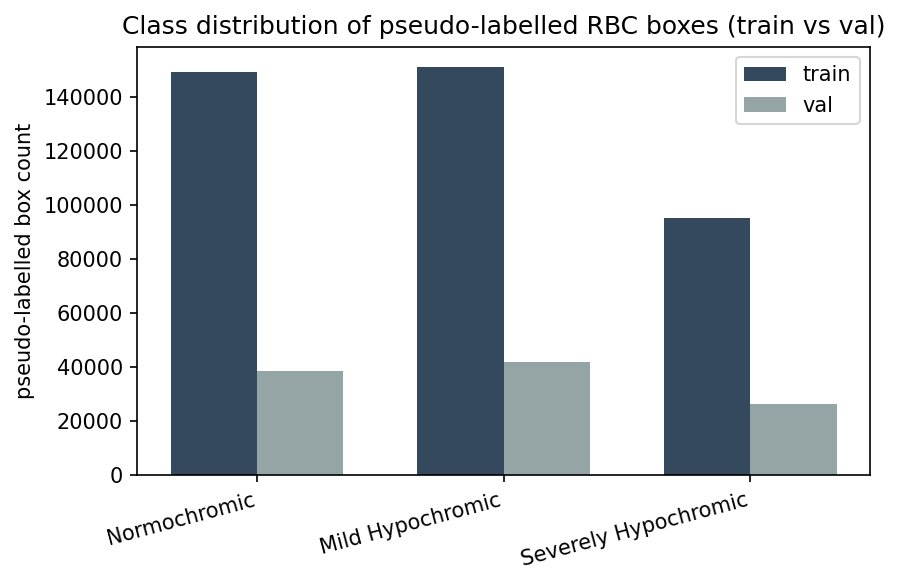

In [10]:
# Class balance, split by train/val
split_counts = (boxes_df.groupby(["split", "class"]).size()
                .unstack(fill_value=0).reindex(columns=CLASSES, fill_value=0)
                .reindex(["train", "val"]))
print(split_counts)

fig, ax = plt.subplots(figsize=(6, 4))
x = np.arange(len(CLASSES))
width = 0.35
for i, split in enumerate(["train", "val"]):
    vals = split_counts.loc[split].values if split in split_counts.index else np.zeros(len(CLASSES))
    ax.bar(x + (i - 0.5) * width, vals, width, label=split,
           color=["#34495e", "#95a5a6"][i])
ax.set_xticks(x)
ax.set_xticklabels([pretty(c) for c in CLASSES], rotation=15, ha="right")
ax.set_ylabel("pseudo-labelled box count")
ax.set_title("Class distribution of pseudo-labelled RBC boxes (train vs val)")
ax.legend()
plt.tight_layout()
plt.show()


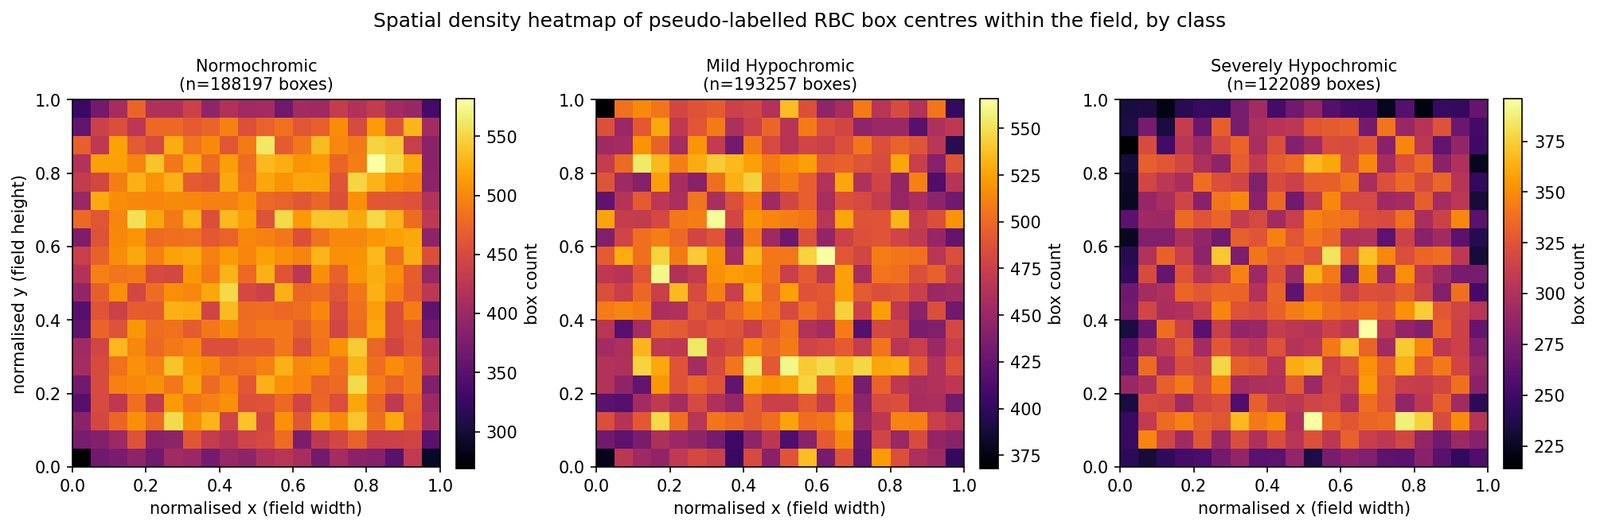

In [11]:
# Spatial density heatmap: where in the field image each class tends to be detected
n_cls = len(CLASSES)
fig, axes = plt.subplots(1, n_cls, figsize=(4.5 * n_cls, 4.5))
axes = np.atleast_1d(axes)

for ax, cls in zip(axes, CLASSES):
    sub = boxes_df[boxes_df["class"] == cls]
    h, xedges, yedges = np.histogram2d(sub["xc"], sub["yc"], bins=20, range=[[0, 1], [0, 1]])
    im = ax.imshow(h.T, origin="lower", extent=[0, 1, 0, 1], cmap="inferno", aspect="equal")
    ax.set_title(f"{pretty(cls)}\n(n={len(sub)} boxes)", fontsize=10)
    ax.set_xlabel("normalised x (field width)")
    if ax is axes[0]:
        ax.set_ylabel("normalised y (field height)")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="box count")

fig.suptitle("Spatial density heatmap of pseudo-labelled RBC box centres within the field, by class",
             fontsize=12)
plt.tight_layout()
plt.show()


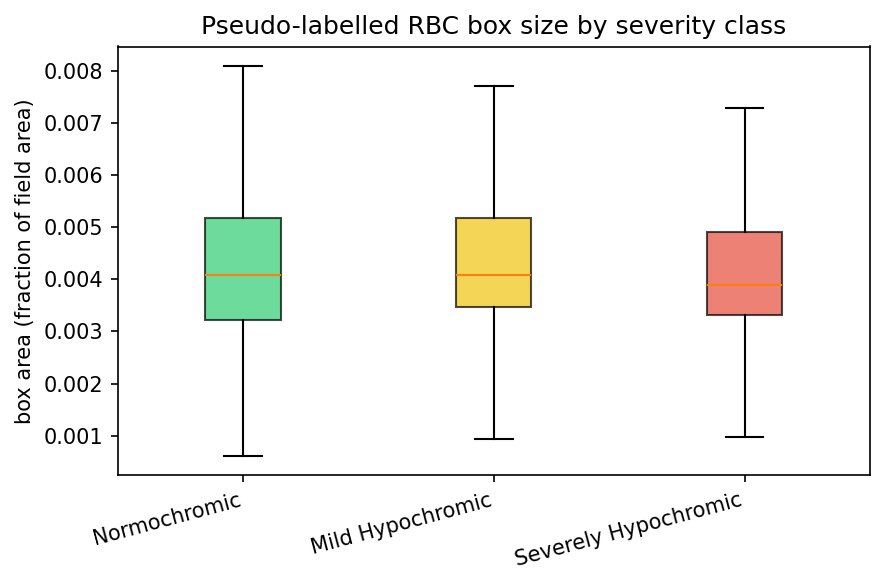

In [12]:
# Box size (area, as a fraction of the field) by class -- sanity check that severity classes
# aren't just an artifact of cell size
fig, ax = plt.subplots(figsize=(6, 4))
data = [boxes_df.loc[boxes_df["class"] == c, "area_frac"].values for c in CLASSES]
bp = ax.boxplot(data, labels=[pretty(c) for c in CLASSES], patch_artist=True, showfliers=False)
for patch, c in zip(bp["boxes"], CLASSES):
    patch.set_facecolor(SEVERITY_COLORS_HEX[c])
    patch.set_alpha(0.7)
ax.set_ylabel("box area (fraction of field area)")
ax.set_title("Pseudo-labelled RBC box size by severity class")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()


## 7. Fine-tune **YOLO26s** (latest Ultralytics model) on the full pseudo-labelled RBC dataset

Upgraded from the reference notebook's YOLOv8s to **YOLO26s** — Ultralytics' current recommended
stable model generation (Jan 2026 release), which is faster and more accurate than YOLOv8/YOLO11 at
the same scale and supports NMS-free end-to-end inference. Same recipe otherwise: AdamW, 640×640,
batch 16, **50 epochs**, over the full dataset built in Section 6.

`pip install -U ultralytics` is important here — YOLO26 support requires a recent Ultralytics release.

In [13]:
!pip -q install -U ultralytics


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.6/46.6 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 16.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.8/75.8 kB 5.1 MB/s eta 0:00:00


In [14]:
from ultralytics import YOLO

YOLO_EPOCHS = 50
YOLO_PATIENCE = 15          # a bit more patience since this run covers the full dataset, not a 300-field sample
YOLO_BATCH = 16
YOLO_IMGSZ = 640
YOLO_BASE_WEIGHTS = "yolo26s.pt"   # latest Ultralytics model generation (COCO-pretrained), released Jan 2026

yolo_model = YOLO(YOLO_BASE_WEIGHTS)

yolo_results = yolo_model.train(
    data=f"{YOLO_ROOT}/data.yaml",
    epochs=YOLO_EPOCHS,
    patience=YOLO_PATIENCE,
    batch=YOLO_BATCH,
    imgsz=YOLO_IMGSZ,
    optimizer="AdamW",
    cos_lr=False,
    seed=SEED,
    project="/kaggle/working/yolo_runs",
    name="rbc_severity_yolo26s_full",
    exist_ok=True,
    verbose=True,
)

YOLO_BEST_PT = str(yolo_model.trainer.best)
print("\nBest checkpoint:", YOLO_BEST_PT)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.150 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fracti

## 8. Validate the trained detector

In [15]:
yolo_model = YOLO(YOLO_BEST_PT)
yolo_model.model.to(device)  # ensure raw nn.Module weights are on the same device as input tensors
yolo_class_names = yolo_model.names
print("Detector classes:", yolo_class_names)

metrics = yolo_model.val(data=f"{YOLO_ROOT}/data.yaml", imgsz=YOLO_IMGSZ, split="val", plots=True)
print(f"\nval mAP@0.5: {metrics.box.map50:.3f}")
print(f"val mAP@0.5:0.95: {metrics.box.map:.3f}")
for i, c in enumerate(CLASSES):
    try:
        print(f"  {pretty(c)} AP@0.5: {metrics.box.ap50[i]:.3f}")
    except Exception:
        pass
print("\nRemember: these numbers reflect agreement with the PSEUDO-labels (central-pallor-ratio "
      "rule), not independent expert ground truth.")

VAL_RUN_DIR = metrics.save_dir
print("\nValidation plots saved to:", VAL_RUN_DIR)

Detector classes: {0: 'Normochromic', 1: 'Mild_Hypochromic', 2: 'Severely_Hypochromic'}
Ultralytics 8.4.150 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26s summary (fused): 120 layers, 9,466,341 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 800.0±359.4 MB/s, size: 24.9 KB)
val: Scanning /kaggle/working/yolo_dataset/labels/val.cache... 1200 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1200/1200 419.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 1% ──────────── 1/75 1.6s/it 0.5s<1:56WARNING ⚠️ NMS time limit 2.800s exceeded
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 75/75 2.1it/s 35.3s
                   all       1200     107394      0.831      0.859      0.918      0.862
          Normochromic       1200      38827      0.877      0.874      0.943      0.875
      Mild_Hypochromic       1188      

## 8a. Confusion matrix + precision/recall/F1 curves

`val(..., plots=True)` above makes Ultralytics save `confusion_matrix.png`, `confusion_matrix_normalized.png`, `BoxPR_curve.png`, and `BoxF1_curve.png` to the run directory. This just displays them inline.

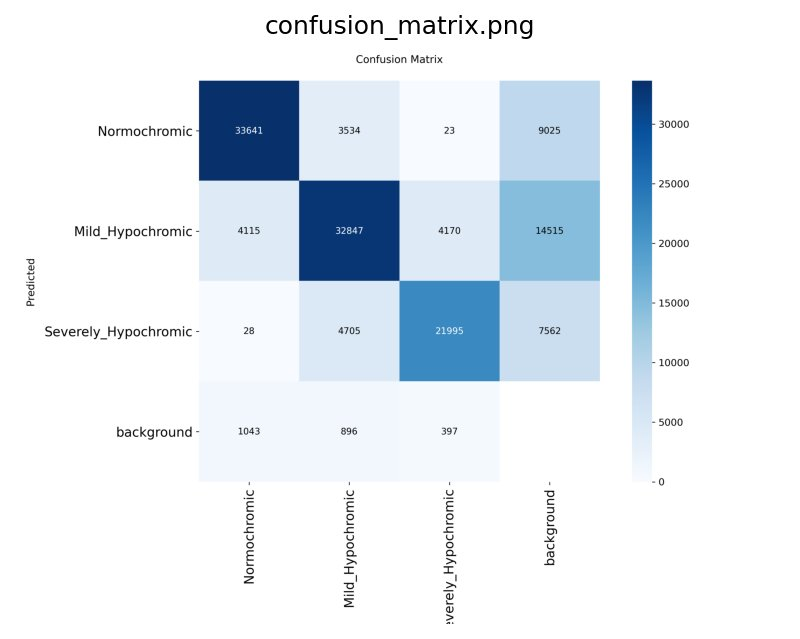

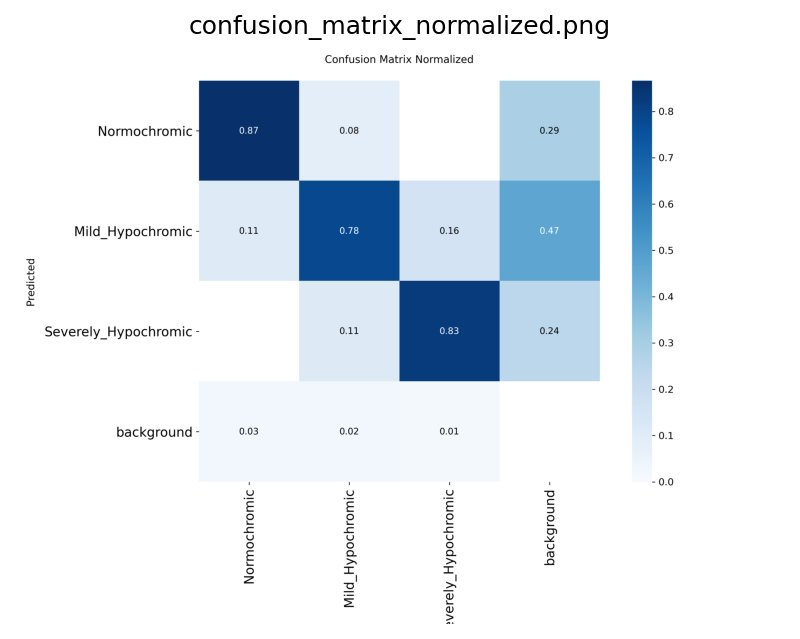

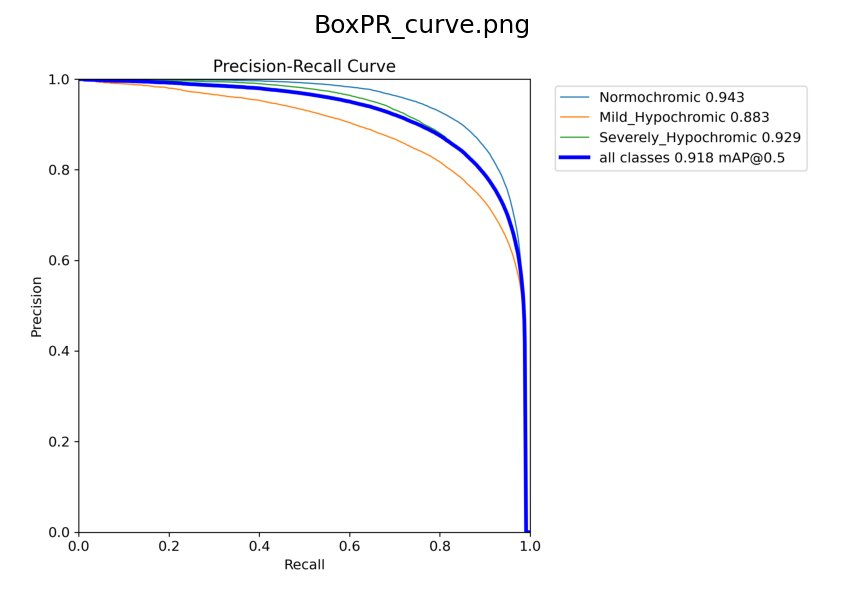

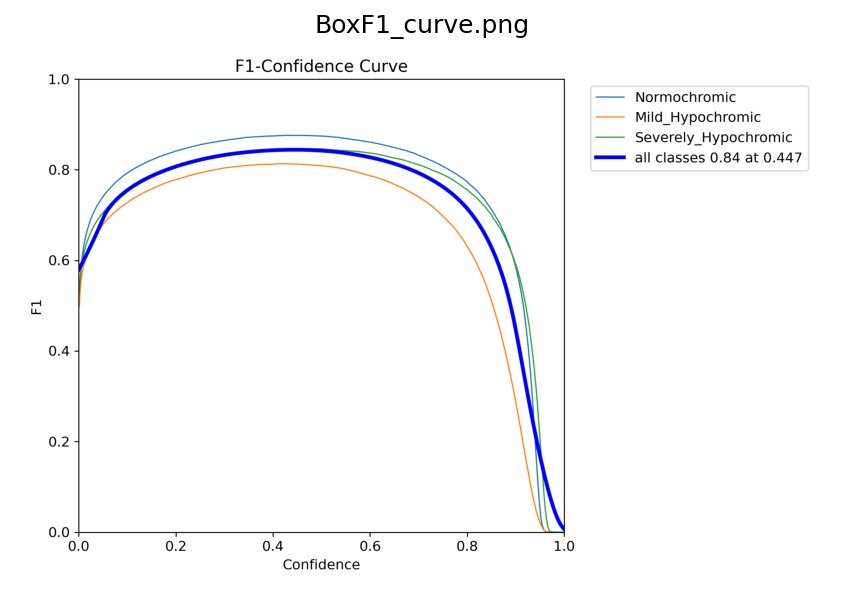

In [16]:
for fname in ["confusion_matrix.png", "confusion_matrix_normalized.png", "BoxPR_curve.png", "BoxF1_curve.png"]:
    fp = os.path.join(VAL_RUN_DIR, fname)
    if os.path.exists(fp):
        img = plt.imread(fp)
        plt.figure(figsize=(7, 5))
        plt.imshow(img); plt.axis("off"); plt.title(fname)
        plt.show()
    else:
        print("Missing:", fp)

## 8b. EigenCAM on the YOLO26 backbone

Same method used in the paper's earlier YOLOv8 explainability figures, run here on the just-trained YOLO26s. YOLO26 keeps the same backbone depth pattern as YOLOv8 (`Conv, Conv, block, Conv, block, Conv, block(P4) ...`), just with `C3k2` blocks in place of `C2f`, so the same layer *index* (6, the P4 feature) is the target layer.

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 37.1 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
EigenCAM target layer: C3k2
Saved: /kaggle/working/yolo26_explainability_outputs/eigencam_grid.png


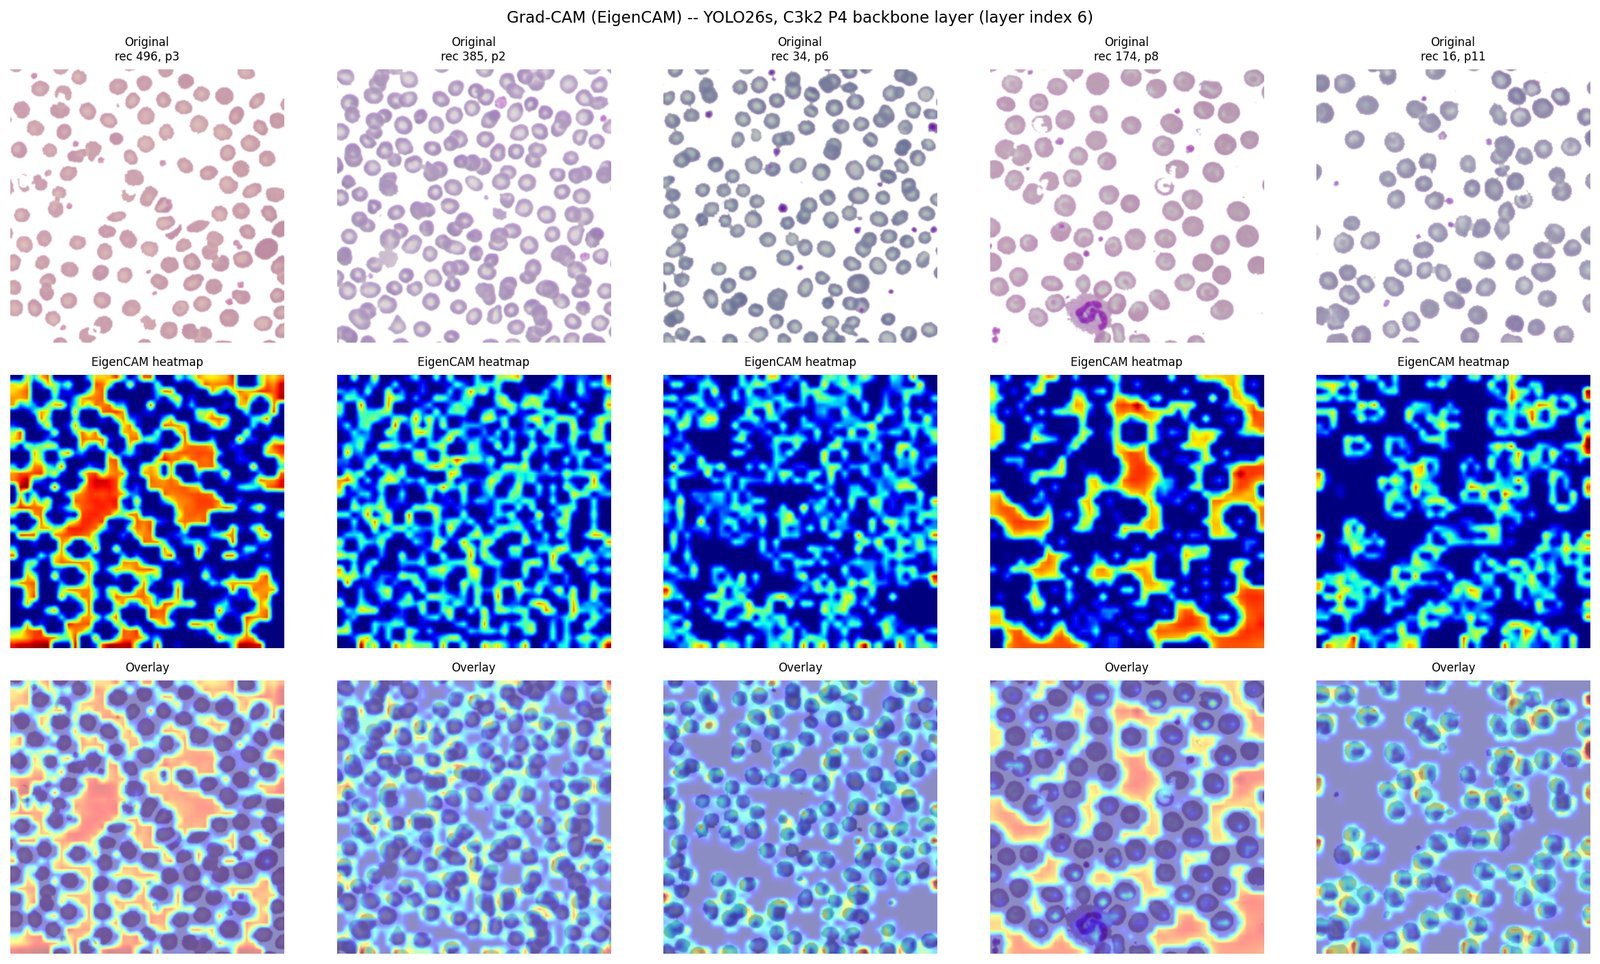

In [17]:
!pip -q install grad-cam==1.5.4

import torch.nn as nn
import torchvision.ops as tvops
from pytorch_grad_cam import EigenCAM
from pytorch_grad_cam.utils.image import show_cam_on_image


class _YoloForwardTensorOnly(nn.Module):
    '''Ultralytics' DetectionModel.forward() in eval mode can return a (predictions, raw_features)
    tuple -- pytorch_grad_cam calls .cpu() on whatever the model returns, which breaks on a tuple.
    This wrapper unwraps it to just the predictions tensor.'''
    def __init__(self, yolo_detection_model):
        super().__init__()
        self.yolo_detection_model = yolo_detection_model

    def forward(self, x):
        out = self.yolo_detection_model(x)
        return out[0] if isinstance(out, (tuple, list)) else out


yolo_model.model.to(device)  # safety net: ensure model is on the same device as input tensors
yolo_cam_model = _YoloForwardTensorOnly(yolo_model.model)

# YOLO26 backbone (nn.Sequential), C3k2-block equivalent of YOLOv8's C2f:
#   0 Conv(P1) 1 Conv(P2) 2 C3k2 3 Conv(P3) 4 C3k2 5 Conv(P4) 6 C3k2  <- P4 backbone feature (40x40 @ 640)
#   7 Conv(P5) 8 C3k2 9 SPPF 10 C2PSA  11.. neck ... Detect head
YOLO_EIGENCAM_LAYER_IDX = 6
eigencam_target_layers = [yolo_model.model.model[YOLO_EIGENCAM_LAYER_IDX]]
print("EigenCAM target layer:", eigencam_target_layers[0].__class__.__name__)


def yolo_letterbox_tensor(rgb_path, imgsz=YOLO_IMGSZ):
    bgr = cv2.imread(rgb_path, cv2.IMREAD_COLOR)
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    resized = cv2.resize(rgb, (imgsz, imgsz))
    img_float = resized.astype(np.float32) / 255.0
    tensor = torch.from_numpy(img_float.transpose(2, 0, 1)).unsqueeze(0).to(device)
    return img_float, tensor


def eigencam_on_field(rgb_path):
    img_float, tensor = yolo_letterbox_tensor(rgb_path)
    with EigenCAM(model=yolo_cam_model, target_layers=eigencam_target_layers) as cam:
        grayscale_cam = cam(tensor)[0]
    overlay = show_cam_on_image(img_float, grayscale_cam, use_rgb=True, image_weight=0.55)
    return (img_float * 255).astype(np.uint8), grayscale_cam, overlay


def eigencam_grid(rgb_paths, titles=None, save_path=None):
    n = len(rgb_paths)
    fig, axes = plt.subplots(3, n, figsize=(3.2 * n, 9.5))
    if n == 1:
        axes = axes.reshape(3, 1)
    for j, p in enumerate(rgb_paths):
        orig, heat, overlay = eigencam_on_field(p)
        t = titles[j] if titles else f"Field {j+1}"
        axes[0, j].imshow(orig); axes[0, j].set_title(f"Original\n{t}", fontsize=8)
        axes[1, j].imshow(heat, cmap="jet"); axes[1, j].set_title("EigenCAM heatmap", fontsize=8)
        axes[2, j].imshow(overlay); axes[2, j].set_title("Overlay", fontsize=8)
        for i in range(3):
            axes[i, j].axis("off")
    fig.suptitle(f"Grad-CAM (EigenCAM) -- YOLO26s, C3k2 P4 backbone layer (layer index {YOLO_EIGENCAM_LAYER_IDX})", fontsize=11)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
        print("Saved:", save_path)
    plt.show()


os.makedirs("/kaggle/working/yolo26_explainability_outputs", exist_ok=True)
FIGS_OUT = "/kaggle/working/yolo26_explainability_outputs"

# Prefer a handful of VALIDATION fields (patients unseen during training)
_eigencam_pool = fields_df[fields_df["record_id"].isin(val_rids)]
if len(_eigencam_pool) == 0:
    _eigencam_pool = fields_df
_sample_fields = _eigencam_pool[["record_id", "patch_id", "rgb_path"]].drop_duplicates().sample(
    min(5, len(_eigencam_pool)), random_state=SEED)

eigencam_grid(
    _sample_fields["rgb_path"].tolist(),
    titles=[f"rec {r}, p{p}" for r, p in zip(_sample_fields["record_id"], _sample_fields["patch_id"])],
    save_path=f"{FIGS_OUT}/eigencam_grid.png",
)

## 8c. D-RISE (Petsiuk et al., 2021) for the YOLO26 detector

### 8c-i. Diagnostic — check the raw output shape FIRST

**Run this before anything else in this section.** YOLO26 is NMS-free with a redesigned, DFL-free detection head, so its raw pre-NMS tensor layout needs to be confirmed before `raw_yolo_forward()` below can be trusted. Expect a 3D tensor shaped `(batch, 4+nc, num_anchors)` or `(batch, num_anchors, 4+nc)` — both are handled automatically; if the printed shape matches neither, `raw_yolo_forward()` needs manual adjustment before the D-RISE cells will produce meaningful saliency maps.

In [18]:
_dbg_img, _dbg_tensor = yolo_letterbox_tensor(fields_df["rgb_path"].iloc[0])
yolo_model.model.to(device)  # safety net: ensure model is on the same device as input tensors
yolo_model.model.eval()
with torch.no_grad():
    _dbg_out = yolo_model.model(_dbg_tensor)
_dbg_preds = _dbg_out[0] if isinstance(_dbg_out, (list, tuple)) else _dbg_out
print("Raw output type:", type(_dbg_out))
print("Raw preds tensor shape:", tuple(_dbg_preds.shape))
print("Sample value range:", float(_dbg_preds.min()), "to", float(_dbg_preds.max()))
print()
print("Expect a 3D tensor whose dims are (batch=1, 4 + num_classes, num_anchors) OR")
print("(batch=1, num_anchors, 4 + num_classes) -- num_classes =", len(CLASSES))
print("If neither matches, raw_yolo_forward() in the next cell needs manual adjustment")
print("before the D-RISE cells below will produce meaningful saliency maps.")

Raw output type: <class 'tuple'>
Raw preds tensor shape: (1, 7, 8400)
Sample value range: -3.406085968017578 to 657.052734375

Expect a 3D tensor whose dims are (batch=1, 4 + num_classes, num_anchors) OR
(batch=1, num_anchors, 4 + num_classes) -- num_classes = 3
If neither matches, raw_yolo_forward() in the next cell needs manual adjustment
before the D-RISE cells below will produce meaningful saliency maps.


In [19]:
def raw_yolo_forward(tensor):
    '''Raw (pre-NMS) YOLO26 output: per-anchor box (xyxy, 640-input pixel space) + per-class scores.
    Auto-detects whether channels are dim 1 or dim 2 based on the diagnostic cell above; edit this
    function directly if the diagnostic printed a shape that doesn't match either case.'''
    yolo_model.model.eval()
    with torch.no_grad():
        out = yolo_model.model(tensor)
    preds = out[0] if isinstance(out, (list, tuple)) else out
    nc = len(CLASSES)
    if preds.shape[1] == 4 + nc:
        preds = preds.transpose(1, 2)  # -> (batch, num_anchors, 4+nc)
    elif preds.shape[2] == 4 + nc:
        pass  # already (batch, num_anchors, 4+nc)
    else:
        raise RuntimeError(f"Unexpected raw output shape {tuple(preds.shape)} -- adjust raw_yolo_forward() manually.")
    boxes_xywh = preds[..., :4]
    scores = preds[..., 4:4 + nc]
    cx, cy, w, h = boxes_xywh[..., 0], boxes_xywh[..., 1], boxes_xywh[..., 2], boxes_xywh[..., 3]
    x1, y1, x2, y2 = cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2
    boxes_xyxy = torch.stack([x1, y1, x2, y2], dim=-1)
    return boxes_xyxy, scores


def raw_detect_nms(tensor, conf_thresh=0.25, iou_thresh=0.5, top_k=50):
    boxes_xyxy, scores = raw_yolo_forward(tensor)
    boxes_xyxy, scores = boxes_xyxy[0], scores[0]
    max_scores, cls_idx = scores.max(dim=1)
    keep_conf = max_scores > conf_thresh
    boxes_xyxy, max_scores, cls_idx, scores = (boxes_xyxy[keep_conf], max_scores[keep_conf],
                                                cls_idx[keep_conf], scores[keep_conf])
    if boxes_xyxy.shape[0] == 0:
        return boxes_xyxy, max_scores, cls_idx, scores
    keep = tvops.nms(boxes_xyxy, max_scores, iou_thresh)[:top_k]
    return boxes_xyxy[keep], max_scores[keep], cls_idx[keep], scores[keep]


def get_raw_detections_for_field(rgb_path, conf_thresh=0.25, iou_thresh=0.5, top_k=20):
    img_float, tensor = yolo_letterbox_tensor(rgb_path)
    boxes_xyxy, max_scores, cls_idx, scores = raw_detect_nms(tensor, conf_thresh, iou_thresh, top_k=top_k)
    dets = []
    for i in range(boxes_xyxy.shape[0]):
        dets.append({
            "box_640": boxes_xyxy[i].detach().cpu().numpy(),
            "score_vec": scores[i].detach().cpu().numpy(),
            "confidence": float(max_scores[i]),
            "label": CLASSES[int(cls_idx[i])],
        })
    return img_float, dets


def _iou_xyxy(box, boxes):
    x1 = torch.maximum(box[0], boxes[:, 0]); y1 = torch.maximum(box[1], boxes[:, 1])
    x2 = torch.minimum(box[2], boxes[:, 2]); y2 = torch.minimum(box[3], boxes[:, 3])
    inter = (x2 - x1).clamp(min=0) * (y2 - y1).clamp(min=0)
    area_box = (box[2] - box[0]) * (box[3] - box[1])
    area_boxes = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])
    union = area_box + area_boxes - inter
    return inter / union.clamp(min=1e-8)


def _generate_random_masks(n_masks, imgsz, grid_size=16, prob_thresh=0.5, rng=None):
    rng = rng or np.random.RandomState(SEED)
    small = (rng.rand(n_masks, grid_size, grid_size) < prob_thresh).astype(np.float32)
    return np.stack([cv2.resize(m, (imgsz, imgsz), interpolation=cv2.INTER_LINEAR) for m in small])


def drise_saliency(rgb_path, target_box_640, target_score_vec, n_masks=800, grid_size=16,
                    prob_thresh=0.5, batch_size=16):
    img_float, _ = yolo_letterbox_tensor(rgb_path)
    imgsz = img_float.shape[0]
    masks = _generate_random_masks(n_masks, imgsz, grid_size=grid_size, prob_thresh=prob_thresh)

    target_box_t = torch.tensor(target_box_640, dtype=torch.float32, device=device)
    target_vec_t = torch.tensor(target_score_vec, dtype=torch.float32, device=device)
    target_vec_norm = target_vec_t / (target_vec_t.norm() + 1e-8)

    saliency = np.zeros((imgsz, imgsz), dtype=np.float32)
    weight_sum = 0.0
    n_done = 0
    while n_done < n_masks:
        b = min(batch_size, n_masks - n_done)
        batch_masks = masks[n_done:n_done + b]
        masked_imgs = img_float[None, ...] * batch_masks[..., None]
        batch_tensor = torch.from_numpy(masked_imgs.transpose(0, 3, 1, 2)).float().to(device)

        boxes_xyxy, scores = raw_yolo_forward(batch_tensor)
        for k in range(b):
            ious = _iou_xyxy(target_box_t, boxes_xyxy[k])
            score_norms = scores[k].norm(dim=1) + 1e-8
            cos_sims = (scores[k] @ target_vec_norm) / score_norms
            match_score = max(0.0, (ious * cos_sims.clamp(min=0)).max().item())
            saliency += batch_masks[k] * match_score
            weight_sum += match_score
        n_done += b

    if weight_sum > 0:
        saliency /= weight_sum
    if saliency.max() > saliency.min():
        saliency = (saliency - saliency.min()) / (saliency.max() - saliency.min())
    return saliency

### 8c-ii. Per-detection D-RISE panels

Saved: /kaggle/working/yolo26_explainability_outputs/drise_per_detection.png


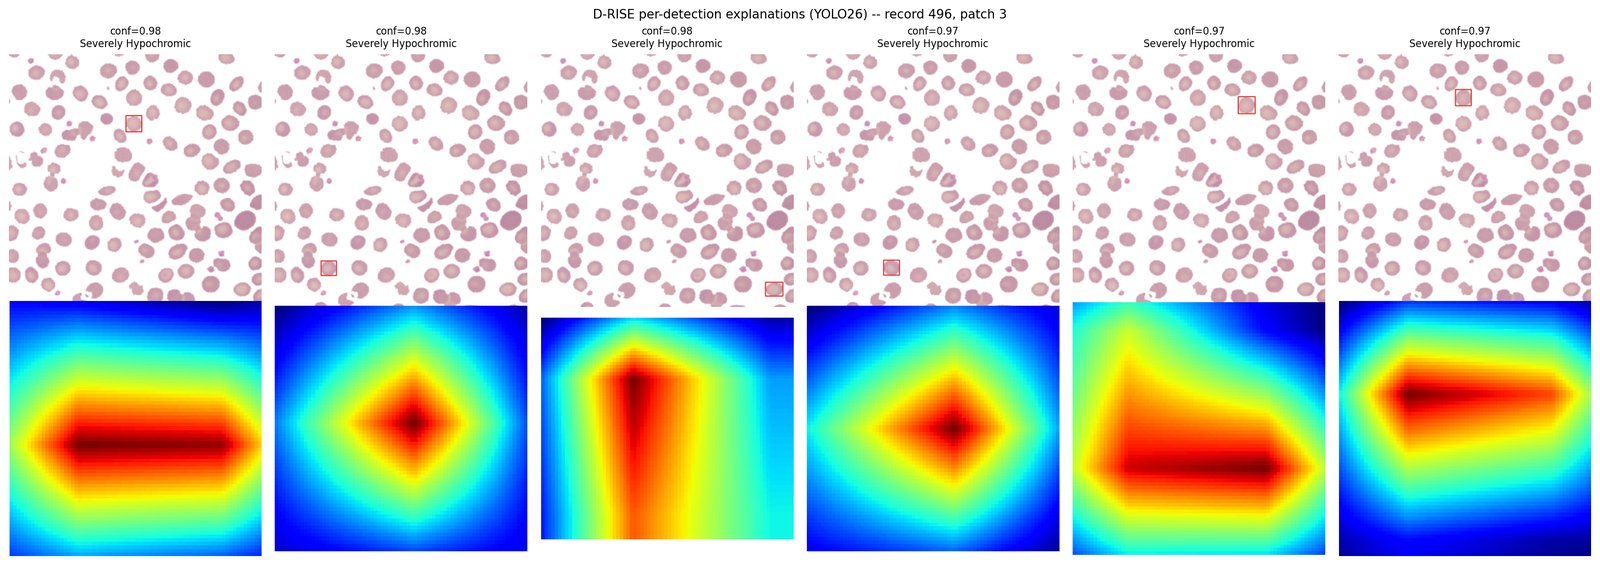

[{'box_640': array([     296.98,      155.93,       336.6,       196.4], dtype=float32),
  'score_vec': array([ 2.7087e-07,   5.351e-08,     0.98414], dtype=float32),
  'confidence': 0.9841383099555969,
  'label': 'Severely_Hypochromic'},
 {'box_640': array([     117.05,      523.98,      156.72,      560.01], dtype=float32),
  'score_vec': array([ 1.5683e-07,  4.1245e-07,     0.97862], dtype=float32),
  'confidence': 0.978621244430542,
  'label': 'Severely_Hypochromic'},
 {'box_640': array([     568.63,      577.94,      612.73,      612.37], dtype=float32),
  'score_vec': array([  1.136e-06,   2.165e-06,     0.97572], dtype=float32),
  'confidence': 0.9757195115089417,
  'label': 'Severely_Hypochromic'},
 {'box_640': array([     194.53,      521.79,      234.14,      559.79], dtype=float32),
  'score_vec': array([ 2.8656e-07,  1.6372e-06,     0.97416], dtype=float32),
  'confidence': 0.9741592407226562,
  'label': 'Severely_Hypochromic'},
 {'box_640': array([     419.94,      107.84,

In [20]:
def plot_drise_per_detection(rgb_path, top_k=6, n_masks=800, grid_size=16, prob_thresh=0.5,
                              save_path=None, title_suffix=""):
    img_float, dets = get_raw_detections_for_field(rgb_path, top_k=top_k)
    if not dets:
        print("No detections above threshold for D-RISE on this field.")
        return []
    dets = sorted(dets, key=lambda d: d["confidence"], reverse=True)[:top_k]
    field_disp = (img_float * 255).astype(np.uint8)

    fig, axes = plt.subplots(2, len(dets), figsize=(3 * len(dets), 6.4))
    if len(dets) == 1:
        axes = axes.reshape(2, 1)

    for j, d in enumerate(dets):
        sal = drise_saliency(rgb_path, d["box_640"], d["score_vec"],
                              n_masks=n_masks, grid_size=grid_size, prob_thresh=prob_thresh)
        x1, y1, x2, y2 = d["box_640"].astype(int)
        disp = field_disp.copy()
        color = tuple(int(v) for v in reversed(SEVERITY_COLORS_BGR[d["label"]]))
        cv2.rectangle(disp, (x1, y1), (x2, y2), color, 2)
        axes[0, j].imshow(disp)
        axes[0, j].set_title(f"conf={d['confidence']:.2f}\n{pretty(d['label'])}", fontsize=8)
        axes[0, j].axis("off")

        pad = 15
        xx0, xx1 = max(0, x1 - pad), min(field_disp.shape[1], x2 + pad)
        yy0, yy1 = max(0, y1 - pad), min(field_disp.shape[0], y2 + pad)
        axes[1, j].imshow(sal[yy0:yy1, xx0:xx1], cmap="jet")
        axes[1, j].axis("off")

    fig.suptitle(f"D-RISE per-detection explanations (YOLO26) {title_suffix}", fontsize=10)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
        print("Saved:", save_path)
    plt.show()
    return dets


_example_row = _sample_fields.iloc[0]
plot_drise_per_detection(
    _example_row["rgb_path"], top_k=6, n_masks=800,
    title_suffix=f"-- record {_example_row['record_id']}, patch {_example_row['patch_id']}",
    save_path=f"{FIGS_OUT}/drise_per_detection.png")

### 8c-iii. Localization validation — saliency-peak-inside-box hit rate vs. a random baseline

In [21]:
def drise_localization_validation(rgb_paths, n_detections_per_field=3, n_masks=500,
                                   grid_size=16, prob_thresh=0.5, seed=SEED):
    records = []
    for rgb_path in tqdm(rgb_paths, desc="D-RISE localization validation"):
        _, dets = get_raw_detections_for_field(rgb_path, top_k=n_detections_per_field)
        for d in dets:
            sal = drise_saliency(rgb_path, d["box_640"], d["score_vec"],
                                  n_masks=n_masks, grid_size=grid_size, prob_thresh=prob_thresh)
            py, px = np.unravel_index(np.argmax(sal), sal.shape)
            x1, y1, x2, y2 = d["box_640"]
            hit = bool((x1 <= px <= x2) and (y1 <= py <= y2))
            cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
            dist = float(math.hypot(px - cx, py - cy))
            diam = float(max(x2 - x1, y2 - y1))
            records.append({"label": d["label"], "hit": hit, "dist": dist, "diam": diam})

    df = pd.DataFrame(records)
    if len(df) == 0:
        print("No detections found on the sampled fields -- widen the sample or lower conf_thresh.")
        return df, None

    rng = np.random.RandomState(seed + 1)
    rand_hits = []
    for rgb_path in rgb_paths:
        _, dets = get_raw_detections_for_field(rgb_path, top_k=n_detections_per_field)
        for d in dets:
            rx, ry = rng.randint(0, YOLO_IMGSZ), rng.randint(0, YOLO_IMGSZ)
            x1, y1, x2, y2 = d["box_640"]
            rand_hits.append(bool((x1 <= rx <= x2) and (y1 <= ry <= y2)))

    overall_hit = df["hit"].mean() * 100
    rand_hit = (np.mean(rand_hits) * 100) if rand_hits else 0.0
    median_dist = df["dist"].median()
    mean_diam = df["diam"].mean()
    per_class = (df.groupby("label")["hit"].mean() * 100).reindex(CLASSES)

    print(f"D-RISE saliency-peak-inside-box hit rate: {overall_hit:.1f}%  (n={len(df)} detections)")
    print(f"Random-pixel baseline hit rate: {rand_hit:.2f}%")
    if rand_hit > 0:
        print(f"-> ~{overall_hit / rand_hit:.0f}x more likely than chance to localize the correct cell")
    print(f"Median peak-to-centre distance: {median_dist:.1f} px "
          f"(mean target-box max-dimension: {mean_diam:.1f} px)")
    print("\nPer-class hit rate (%):")
    print(per_class.round(1))
    return df, rand_hit


N_FIELDS_FOR_VALIDATION = 15
_val_pool = fields_df[fields_df["record_id"].isin(val_rids)]
_val_fields = _val_pool["rgb_path"].drop_duplicates().sample(
    min(N_FIELDS_FOR_VALIDATION, _val_pool["rgb_path"].nunique()), random_state=SEED).tolist()
drise_val_df, drise_rand_hit = drise_localization_validation(_val_fields, n_detections_per_field=3, n_masks=500)

D-RISE localization validation:   0%|          | 0/15 [00:00<?, ?it/s]

D-RISE saliency-peak-inside-box hit rate: 80.0%  (n=45 detections)
Random-pixel baseline hit rate: 0.00%
Median peak-to-centre distance: 17.8 px (mean target-box max-dimension: 43.0 px)

Per-class hit rate (%):
label
Normochromic              0.0
Mild_Hypochromic        100.0
Severely_Hypochromic     87.2
Name: hit, dtype: float64


## 9. Quick visual check on one field

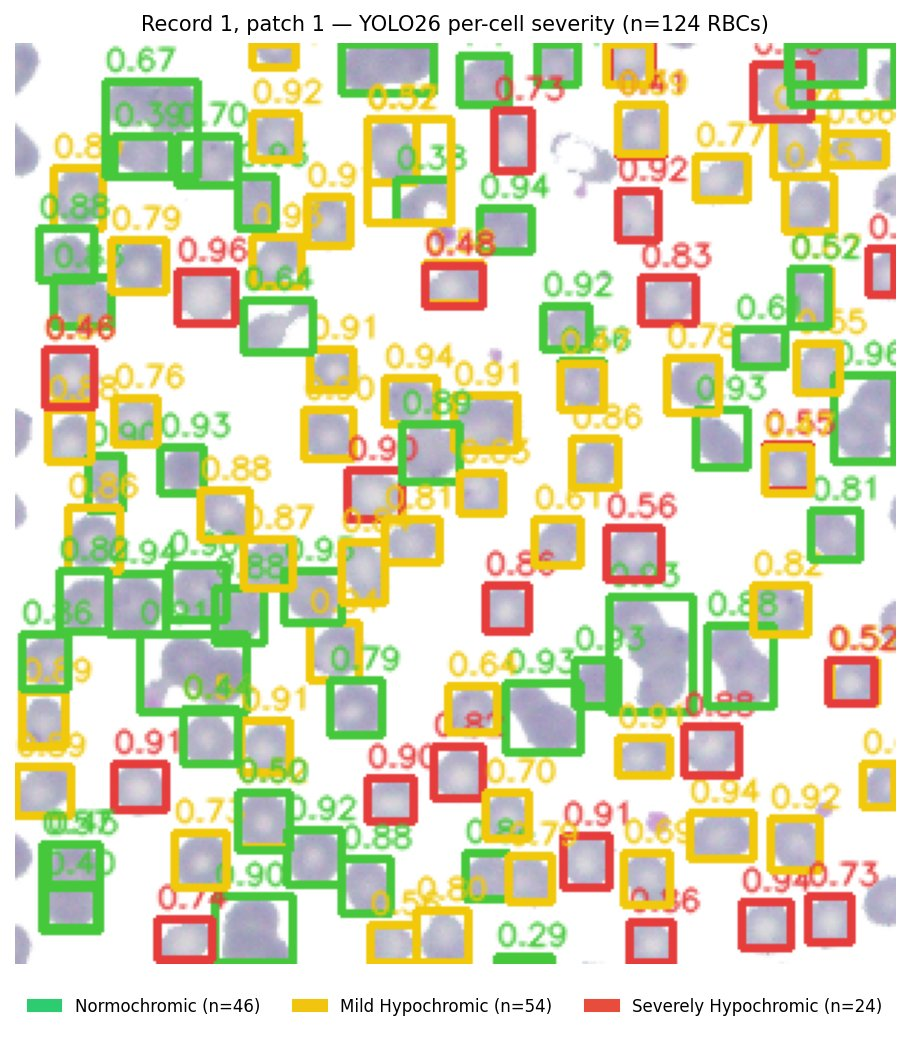

In [22]:
YOLO_CONF_THRESH = 0.25
YOLO_IOU_THRESH = 0.5
_yolo_idx_to_class = {i: name for i, name in yolo_class_names.items()}


def run_detector_on_field(rgb_path):
    result = yolo_model.predict(source=rgb_path, conf=YOLO_CONF_THRESH, iou=YOLO_IOU_THRESH,
                                 imgsz=YOLO_IMGSZ, verbose=False)[0]
    bgr = cv2.imread(rgb_path, cv2.IMREAD_COLOR)
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

    dets = []
    boxes = result.boxes
    if boxes is not None:
        xyxy = boxes.xyxy.cpu().numpy()
        confs = boxes.conf.cpu().numpy()
        clss = boxes.cls.cpu().numpy().astype(int)
        for (x1, y1, x2, y2), conf, cls_idx in zip(xyxy, confs, clss):
            label = _yolo_idx_to_class.get(int(cls_idx))
            if label is None:
                continue
            dets.append({"bbox": (int(x1), int(y1), int(x2 - x1), int(y2 - y1)),
                         "label": label, "confidence": float(conf)})
    return rgb, dets


def draw_cell_boxes(rgb_field, cell_results):
    out = rgb_field.copy()
    for c in cell_results:
        label = c["label"]
        if label not in SEVERITY_COLORS_BGR:
            continue
        x, y, w, h = c["bbox"]
        color = tuple(int(v) for v in reversed(SEVERITY_COLORS_BGR[label]))
        cv2.rectangle(out, (x, y), (x + w, y + h), color, 2)
        cv2.putText(out, f"{c['confidence']:.2f}", (x, max(0, y - 4)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.35, color, 1, cv2.LINE_AA)
    return out


_ex_row = fields_df.iloc[0]
rgb, dets = run_detector_on_field(_ex_row["rgb_path"])
annotated = draw_cell_boxes(rgb, dets)

counts = {c: sum(1 for d in dets if d["label"] == c) for c in CLASSES}
fig, ax = plt.subplots(1, 1, figsize=(7, 7))
ax.imshow(annotated)
ax.set_title(f"Record {_ex_row['record_id']}, patch {_ex_row['patch_id']} — YOLO26 per-cell severity "
             f"(n={len(dets)} RBCs)", fontsize=10)
ax.axis("off")
handles = [mpatches.Patch(color=SEVERITY_COLORS_HEX[c], label=f"{pretty(c)} (n={counts[c]})") for c in CLASSES]
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=len(CLASSES), frameon=False, fontsize=8)
plt.tight_layout()
plt.show()


## 9b. YOLO detection grid across multiple validation fields

The single-field check above is easy to over-read. Here the trained YOLO26 detector is run on a
small random sample of *validation* fields (patients unseen during training) side by side, so the
per-cell severity calls can be eyeballed across different patients rather than one lucky/unlucky
image.


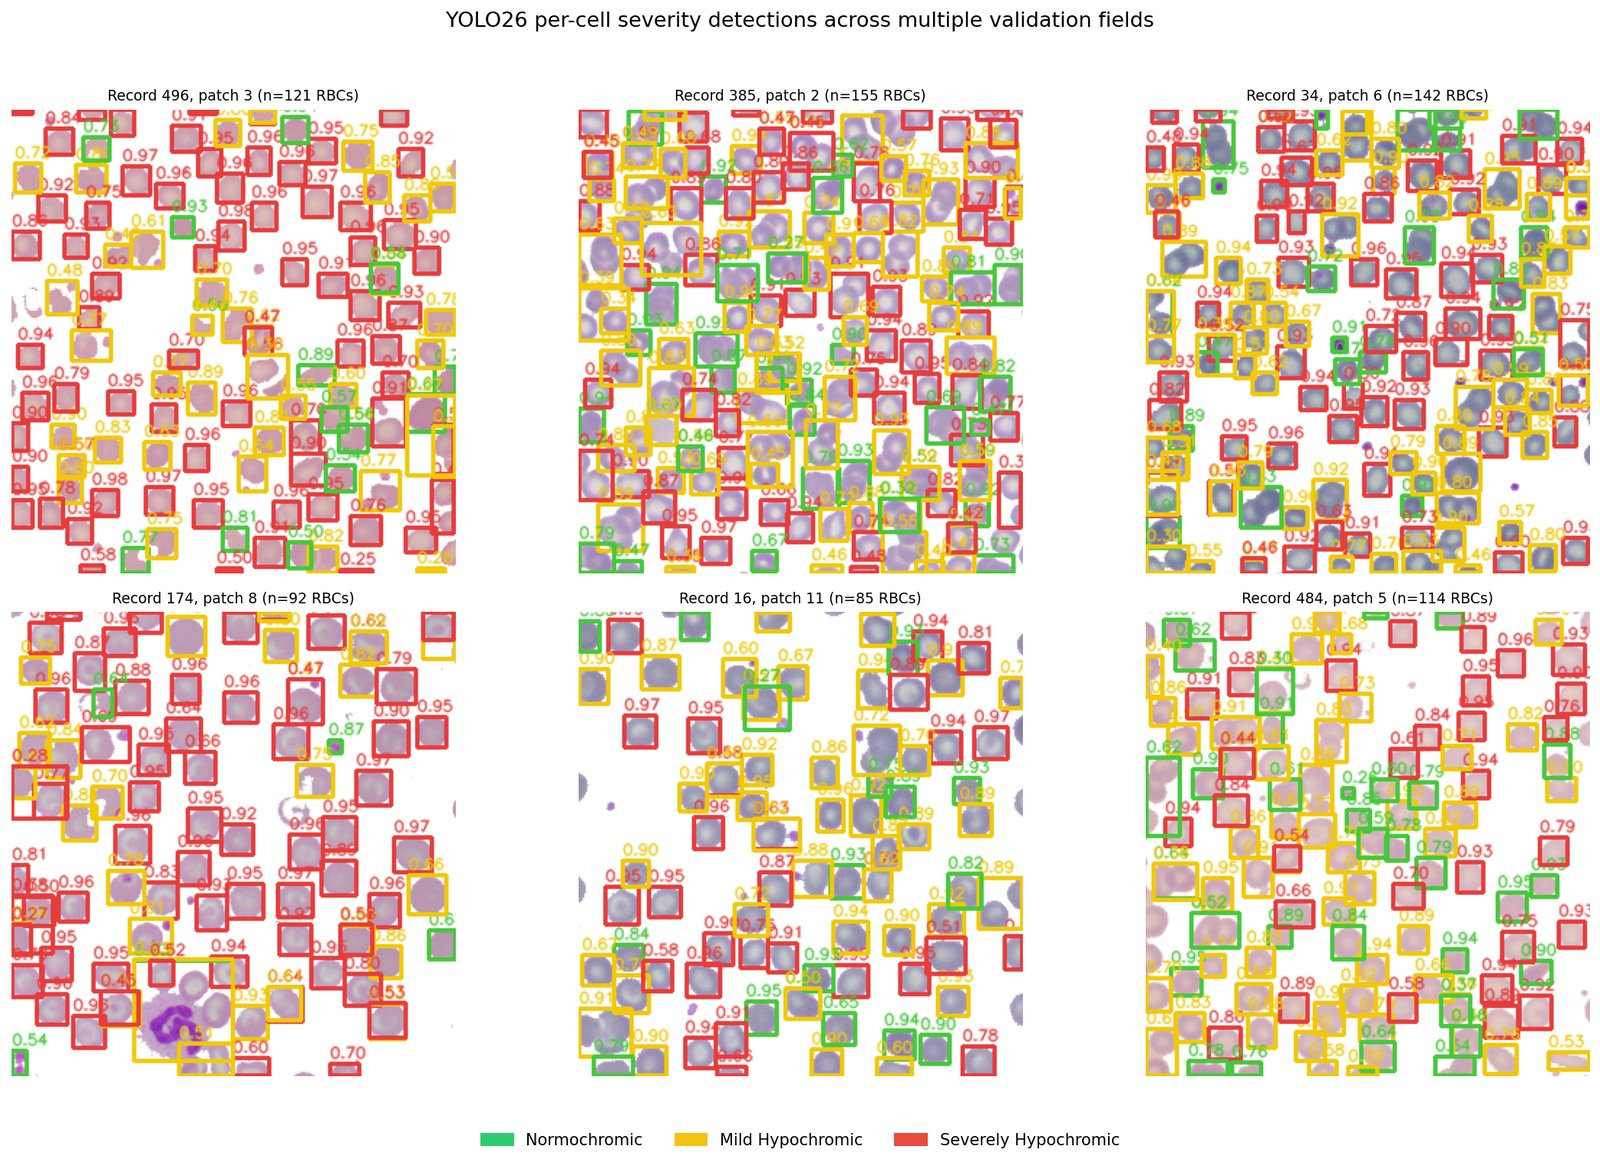

In [23]:
val_fields_df = fields_df[fields_df["record_id"].isin(val_rids)].reset_index(drop=True)
n_show = min(6, len(val_fields_df))
sample_rows = (val_fields_df.sample(n=n_show, random_state=SEED)
               if len(val_fields_df) >= n_show else val_fields_df)

n_cols = 3
n_rows = math.ceil(n_show / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 5 * n_rows))
axes = np.atleast_1d(axes).flatten()

for ax, (_, row) in zip(axes, sample_rows.iterrows()):
    rgb, dets = run_detector_on_field(row["rgb_path"])
    annotated = draw_cell_boxes(rgb, dets)
    ax.imshow(annotated)
    ax.set_title(f"Record {row['record_id']}, patch {row['patch_id']} (n={len(dets)} RBCs)", fontsize=9)
    ax.axis("off")

for ax in axes[n_show:]:
    ax.axis("off")

handles = [mpatches.Patch(color=SEVERITY_COLORS_HEX[c], label=pretty(c)) for c in CLASSES]
fig.legend(handles=handles, loc="lower center", ncol=len(CLASSES), frameon=False,
           fontsize=10, bbox_to_anchor=(0.5, -0.02))
fig.suptitle("YOLO26 per-cell severity detections across multiple validation fields", fontsize=13)
plt.tight_layout(rect=[0, 0.04, 1, 0.96])
plt.show()


## 10. Save the trained detector for later use

Zips the best checkpoint + `data.yaml` so it can be downloaded and reused (e.g. as the detector in
a later explainability notebook, the same way `Ran_Normochromic...` fed the earlier one).

In [24]:
import shutil

SAVE_DIR = "/kaggle/working/yolo26_rbc_severity_results"
os.makedirs(SAVE_DIR, exist_ok=True)
shutil.copy(YOLO_BEST_PT, os.path.join(SAVE_DIR, "best_yolo26s_rbc_severity.pt"))
shutil.copy(f"{YOLO_ROOT}/data.yaml", os.path.join(SAVE_DIR, "data.yaml"))

zip_path = "/kaggle/working/yolo26_rbc_severity_results.zip"
shutil.make_archive(zip_path.replace(".zip", ""), "zip", SAVE_DIR)
print("Saved:", zip_path)


Saved: /kaggle/working/yolo26_rbc_severity_results.zip
